In [24]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", palette="colorblind")

In [25]:
ROOT = Path("..").resolve()
RESULTS = ROOT / "results"

RUNS = {
    "Base": RESULTS / "base",
    "SFT 6k": RESULTS / "sft-6k",
    "Repetition E8": RESULTS / "sft-6k-repetition-epoch-8",
    "Repetition E16": RESULTS / "sft-6k-repetition-epoch-16",
}

rows = []

for run, directory in RUNS.items():
    for path in directory.rglob("metrics.json"):
        data = json.loads(path.read_text())

        for task in data["tasks"]:
            rows.append({
                "run": run,
                "task": task["alias"],
                "score": task["metrics"]["primary_score"],
                "n": task["num_instances"],
                "source": str(path.relative_to(ROOT)),
            })

df = pd.DataFrame(rows)

## AIME 2024

In [26]:
df[df["task"] == "aime:2024::olmo3:adapt"]

,run,task,score,n,source
0,Base,aime:2024::olmo3:adapt,0.100000,30,results/base/aime-2024-2025-r8/metrics.json
4,SFT 6k,aime:2024::olmo3:adapt,0.295833,30,results/sft-6k/aime-2024-2025-r8/metrics.json
8,Repetition E8,aime:2024::olmo3:adapt,0.483333,30,results/sft-6k-repetition-epoch-8/aime-2024-20...
12,Repetition E16,aime:2024::olmo3:adapt,0.450000,30,results/sft-6k-repetition-epoch-16/aime-2024-2...


## AIME 2025

In [27]:
df[df["task"] == "aime:2025::olmo3:adapt"]

,run,task,score,n,source
1,Base,aime:2025::olmo3:adapt,0.150000,30,results/base/aime-2024-2025-r8/metrics.json
5,SFT 6k,aime:2025::olmo3:adapt,0.262500,30,results/sft-6k/aime-2024-2025-r8/metrics.json
9,Repetition E8,aime:2025::olmo3:adapt,0.295833,30,results/sft-6k-repetition-epoch-8/aime-2024-20...
13,Repetition E16,aime:2025::olmo3:adapt,0.325000,30,results/sft-6k-repetition-epoch-16/aime-2024-2...


## GPQA

In [28]:
df[df["task"] == "gpqa::olmo3:adapt"]

,run,task,score,n,source
2,Base,gpqa::olmo3:adapt,0.287946,448,results/base/gpqa/metrics.json
6,SFT 6k,gpqa::olmo3:adapt,0.323661,448,results/sft-6k/gpqa/metrics.json
10,Repetition E8,gpqa::olmo3:adapt,0.395089,448,results/sft-6k-repetition-epoch-8/gpqa/metrics...
14,Repetition E16,gpqa::olmo3:adapt,0.426339,448,results/sft-6k-repetition-epoch-16/gpqa/metric...


## Minerva MATH500

In [29]:
df[df["task"] == "minerva_math_500::hamish_zs_reasoning"]

,run,task,score,n,source
3,Base,minerva_math_500::hamish_zs_reasoning,0.630,500,results/base/math500/metrics.json
7,SFT 6k,minerva_math_500::hamish_zs_reasoning,0.884,500,results/sft-6k/math500/metrics.json
11,Repetition E8,minerva_math_500::hamish_zs_reasoning,0.908,500,results/sft-6k-repetition-epoch-8/math500/metr...
15,Repetition E16,minerva_math_500::hamish_zs_reasoning,0.910,500,results/sft-6k-repetition-epoch-16/math500/met...


## Benchmark progression

Base → SFT 6k → Repetition E8 → Repetition E16.

Primary Score in %

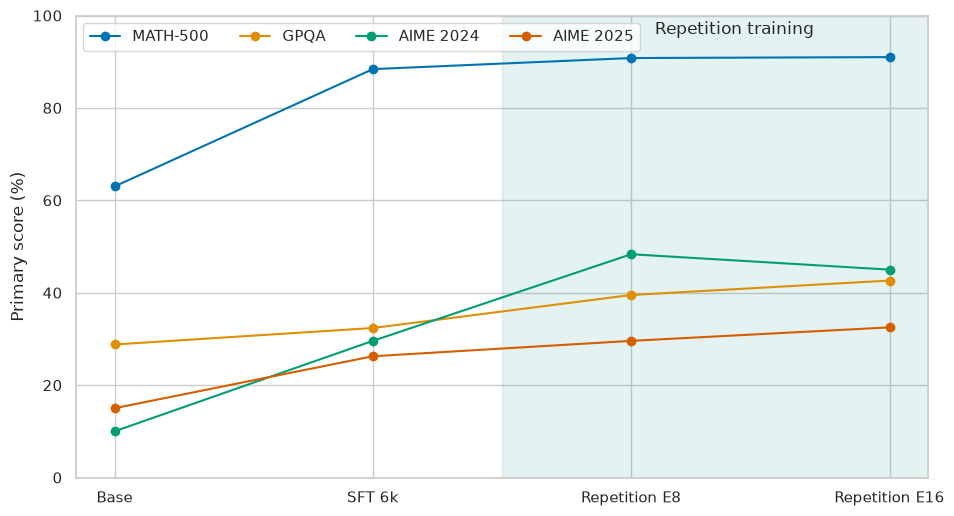

In [30]:
benchmarks = {
    "minerva_math_500::hamish_zs_reasoning": "MATH-500",
    "gpqa::olmo3:adapt": "GPQA",
    "aime:2024::olmo3:adapt": "AIME 2024",
    "aime:2025::olmo3:adapt": "AIME 2025",
}

scores = (df.pivot(index="run", columns="task", values="score")
          .reindex(index=RUNS, columns=benchmarks)
          .rename(columns=benchmarks) * 100)

fig, ax = plt.subplots(figsize=(11, 6))
scores.plot(ax=ax, marker="o")
ax.axvspan(1.5, 11, color="teal", alpha=0.1)
ax.text(2.4, 96, "Repetition training", ha="center")
ax.set(
    xticks=range(len(scores)),
    xticklabels=scores.index,
    ylim=(0, 100),
    xlim=(-0.15, 3.15),
    xlabel="",
    ylabel="Primary score (%)")
ax.legend(ncol=4, loc="upper left")
ax.grid(axis="y", visible=True)
plt.show()

## Benchmark profiles

Axes use 0–100%. The dashed outline is Base.

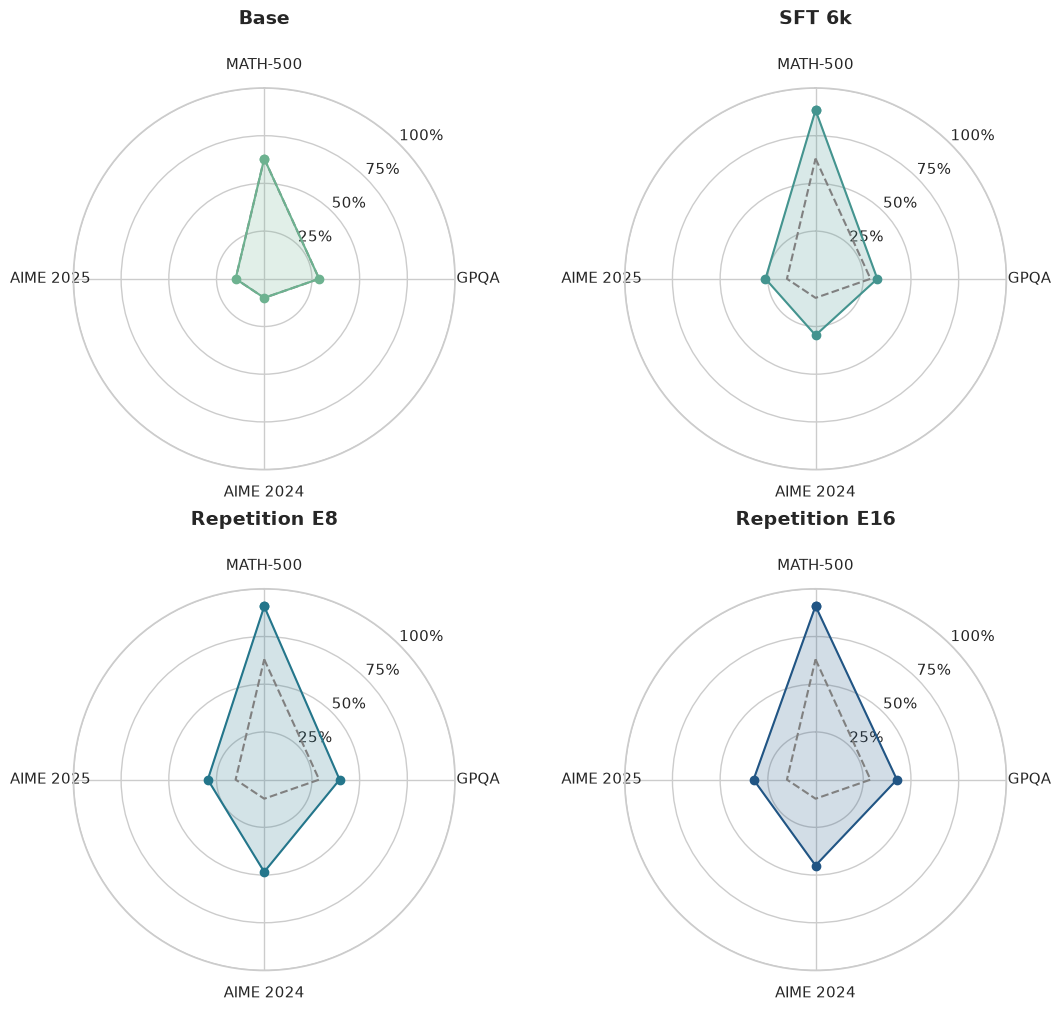

In [31]:
angles = np.linspace(0, 2 * np.pi, len(scores.columns), endpoint=False)
closed_angles = np.r_[angles, angles[0]]
base = scores.loc["Base"].to_numpy()
run_colors = sns.color_palette("crest", len(scores))


def setup_radar(ax):
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set(xticks=angles, xticklabels=scores.columns, ylim=(0, 100),
           yticks=[25, 50, 75, 100], yticklabels=["25%", "50%", "75%", "100%"])
    ax.set_rlabel_position(45)


fig, axes = plt.subplots(2, 2, figsize=(11, 10),
                         subplot_kw={"projection": "polar"}, layout="constrained")

for ax, (run, values), color in zip(axes.flat, scores.iterrows(), run_colors):
    setup_radar(ax)
    values = np.r_[values, values.iloc[0]]
    ax.plot(closed_angles, np.r_[base, base[0]], color="gray", linestyle="--")
    ax.plot(closed_angles, values, color=color, marker="o")
    ax.fill(closed_angles, values, color=color, alpha=0.2)
    ax.set_title(run, pad=24, fontweight="bold", fontsize=14)
plt.show()

## Score changes

Left: gain over Base

Right: gain over the previous checkpoint

Values in %

Both plots share a color scale

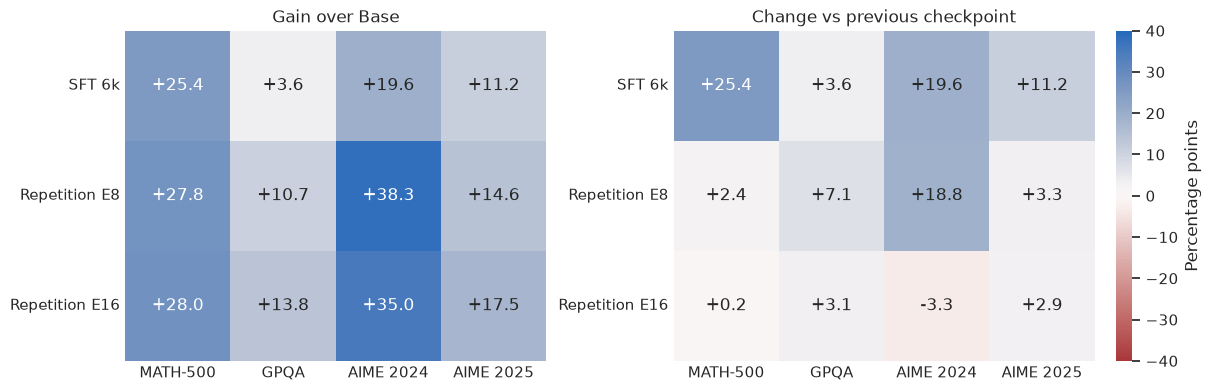

In [39]:
gains = scores.subtract(scores.loc["Base"]).iloc[1:]
changes = scores.diff().iloc[1:]
max_change = pd.concat([gains, changes]).abs().to_numpy().max()
limit = 5 * np.ceil(max_change / 5)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
for ax, values, title in zip(axes, 
                             [gains, changes],
                             ["Gain over Base", "Change vs previous checkpoint"]):
    sns.heatmap(values, ax=ax, annot=values.map("{:+.1f}".format), fmt="",
                cmap="vlag_r", center=0, vmin=-limit, vmax=limit,
                cbar=ax is axes[1], cbar_kws={"label": "Percentage points"})
    ax.set(title=title, xlabel="", ylabel="")
    ax.tick_params(axis="both", length=0)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.show()

## Base, SFT 6k and Repetition E16

Overlaid benchmark profiles on the same 0–100% scale.


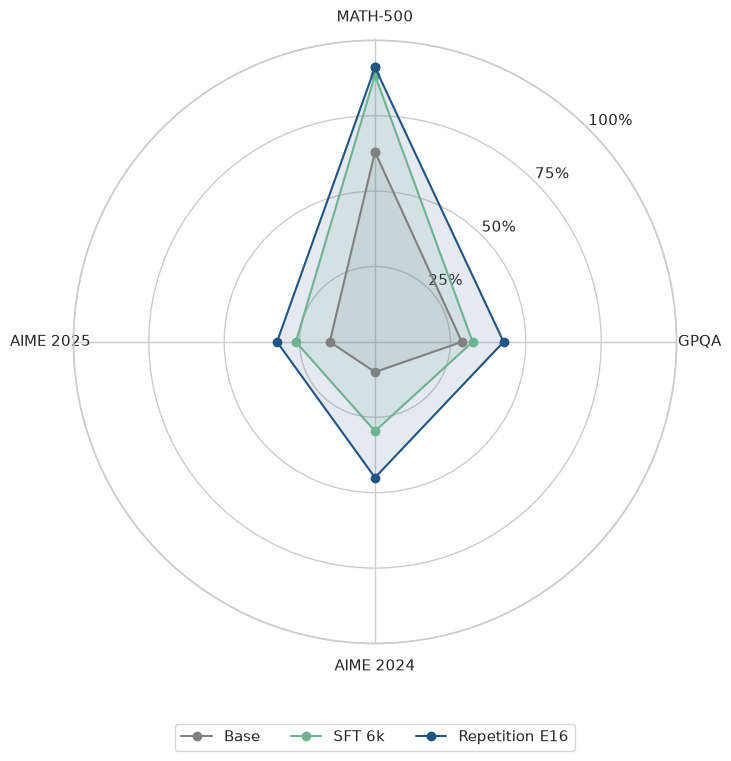

In [43]:
comparison = scores.loc[["Base", "SFT 6k", "Repetition E16"]]

fig, ax = plt.subplots(figsize=(8, 7.5), subplot_kw={"projection": "polar"},
                       layout="constrained")
setup_radar(ax)
for (run, values), color in zip(comparison.iterrows(), ["gray", "#6DB390", "#215584"]):
    values = np.r_[values, values.iloc[0]]
    ax.plot(closed_angles, values, label=run, color=color, marker="o")
    ax.fill(closed_angles, values, color=color, alpha=0.12)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
plt.show()

## Scores by benchmark

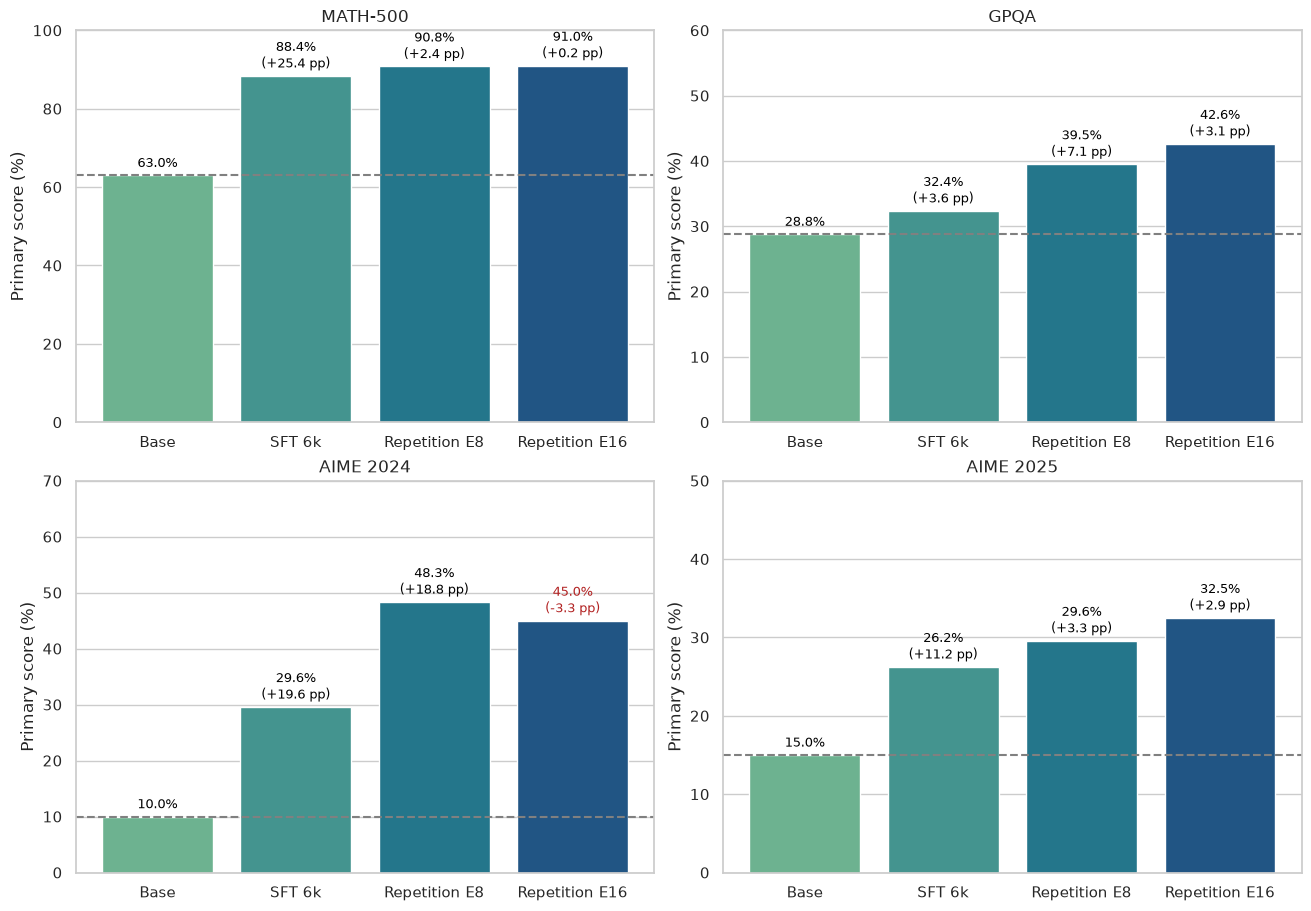

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9), layout="constrained")
for ax, benchmark in zip(axes.flat, scores.columns):
    values = scores[benchmark].to_numpy()
    bars = ax.bar(scores.index, values, color=run_colors)
    ax.axhline(values[0], color="gray", linestyle="--")
    for i, (bar, value) in enumerate(zip(bars, values)):
        label = f"{value:.1f}%"
        delta = value - values[i - 1] if i else 0
        if i:
            label += f"\n({delta:+.1f} pp)"
        ax.annotate(label, (bar.get_x() + bar.get_width() / 2, value),
                    xytext=(0, 6), textcoords="offset points", ha="center",
                    fontsize=9, color="firebrick" if delta < 0 else "black")
    ax.set(title=benchmark, ylabel="Primary score (%)",
           ylim=(0, min(100, np.ceil((values.max() + 12) / 10) * 10)))
    ax.grid(axis="x", visible=False)
plt.show()